### Dreiecksbeziehungen – Lösung Schritt für Schritt

*37. Bundeswettbewerb Informatik (2018/2019), 2. Runde, Aufgabe 2*

Der seltsame Klub der wohlhabenden Trianguläre will entlang der schnurgeraden Küstenstraße auf der Landseite eine neue Siedlung
gründen. Jedes Klubmitglied hat sich für eine dreieckige Grundstücksform entschieden, deren Größe und Winkel seine Persönlichkeit zum
Ausdruck bringen. Jetzt gilt es, die Grundstücke entlang der Straße so unterzubringen, dass jedes Grundstück mindestens eine Ecke an der
Straße hat, damit der Zugang zum Grundstück gesichert ist.

Alle Ecken eines Grundstücks an der Straße heißen Straßenecken. Der Abstand zwischen zwei Grundstücken ist die kleinste Distanz zwischen
einer Straßenecke des einen und einer Straßenecke des anderen Grundstücks. Die Klubmitglieder möchten so eng beieinander wohnen, wie es
ihre Grundstücke erlauben. Daher soll der Abstand zwischen den am weitesten voneinander entfernten Grundstücken (Gesamtabstand)
möglichst gering sein. Wie die Trianguläre entdecken, ist es gar nicht so leicht, die optimale Platzierung aller Grundstücke
herauszufinden. Im hier abgebildeten Beispiel lässt sich der Gesamtabstand bestimmt noch weiter verringern. *(Das Bild des
Aufgabenblatts fehlt hier.)*

#### Aufgabe

Schreibe ein Programm, das eine Liste von Grundstücken in Dreiecksform einliest und sie so platziert, dass eine Ecke oder eine Kante
jedes Dreiecks an der Küstenstraße (der x-Achse des Koordinatensystems) liegt und der Gesamtabstand möglichst klein ist.

Das Programm soll Folgendes ausgeben: (a) eine Visualisierung der Lage der Dreiecke entlang der x-Achse wie im hier abgebildeten
Beispiel sowie (b) die berechnete Folge der Dreiecke, aufsteigend sortiert nach ihrer Platzierung entlang der x-Achse, mit den
Koordinatenpaaren (x, y) aller drei Ecken jedes Grundstücks.

Wende dein Programm auf alle Beispiele an, die du auf den BWINF-Webseiten findest; das Datenformat ist dort erläutert. Dokumentiere die
Ergebnisse.

#### Beispieldaten

Im Ordner `beispieldaten` stehen `dreiecke1.txt` bis `dreiecke5.txt`, dazu je eine Zeichnung `.svg`. Die Erläuterung des Formats ist im
Archiv nicht mehr vorhanden; aus den Dateien abgelesen: Zeile 1 enthält die Zahl `n` der Dreiecke, danach steht jedes Dreieck in einer
Zeile als `3 x1 y1 x2 y2 x3 y3` (die Zahl der Ecken, dann die Koordinaten der drei Ecken). Die Dreiecke liegen dort irgendwo im
Koordinatensystem, teils gar nicht an der Straße. Wir nummerieren sie wie die Lösungshinweise ab 0 (in den `.svg`-Dateien heißen sie
`D1`, `D2`, …).

## Was dir bei dieser Aufgabe hilft

**Algorithmische Kenntnisse**
- **Heuristik:** Die Lösungshinweise gehen davon aus, dass die Aufgabe NP-schwer ist (ähnliche Packprobleme sind es). Eine beste
  Anordnung findet man für 37 Dreiecke nicht in vernünftiger Zeit. Man baut deshalb mit einer **Faustregel** eine gute Anordnung und
  vergleicht ehrlich mit den Zahlen der Hinweise.
- **Gieriges Verfahren (Greedy):** Die Siedlung wächst von links nach rechts; in jedem Schritt nimmt man das Dreieck in der Lage, die
  im Moment am besten aussieht, und ändert es danach nicht mehr.
- **Zufall (Randomisierung):** Lässt man das gierige Verfahren in jedem Schritt zufällig die Hälfte der Dreiecke übersehen, entstehen
  viele verschiedene Siedlungen; man behält die beste.
- **Geometrie:** Winkel mit `atan2`, Drehen mit `cos` und `sin`, Schwerpunkt eines Dreiecks (Mittelwert der Ecken), Schnittpunkt einer
  waagerechten Geraden mit einer Strecke (lineares Einsetzen).
- **Trennungssatz:** Zwei Dreiecke überlappen sich genau dann **nicht**, wenn es eine Dreieckskante gibt, auf deren Senkrechte die
  „Schatten“ (Projektionen) der beiden Dreiecke nicht überlappen. Damit bauen wir einen Schiedsrichter, der jede Siedlung prüft.
- **Toleranzen bei Kommazahlen:** Dreiecke sollen sich berühren dürfen. Rundungsfehler von etwa `0,000 000 000 001` dürfen dabei
  nicht als Überlappung zählen.

**Nützliche Funktionen und Bibliotheken**
- `math.atan2(dy, dx)` (Richtung eines Pfeils als Winkel), `math.degrees`, `math.radians`, `math.cos`, `math.sin`,
  `math.hypot(dx, dy)` (Länge eines Pfeils).
- `random.Random(zahl)`: ein Zufallsgenerator, der bei gleicher Zahl immer dieselben Zufallszahlen liefert; `.random()` gibt eine
  Kommazahl zwischen 0 und 1.
- `matplotlib.pyplot` mit `matplotlib.patches.Polygon` zum Zeichnen der Dreiecke.

## Die Idee in Worten

**Wie ein Dreieck an der Straße liegt.** Ein Dreieck berührt die Straße mit (mindestens) einer Ecke `E` und liegt ganz auf der
Landseite (`y ≥ 0`). Hat es an `E` den Winkel `w`, dann zeigen seine beiden Kanten von `E` aus in die Richtungen `phi` und `phi + w`
(gemessen gegen den Uhrzeigersinn von der positiven x-Achse aus). Damit es über der Straße bleibt, muss `0 ≤ phi` und `phi + w ≤ 180`
sein. Bei `phi = 0` oder `phi + w = 180` liegt eine Kante auf der Straße. Dazu kommt, welche der beiden Kanten zuerst kommt (das ist
das gespiegelte Dreieck). Jede Lage ist also: Ecke, Seite, Drehwinkel `phi` und Lage von `E` auf der x-Achse.

**Fächer.** Legt man mehrere Dreiecke mit einer Ecke an denselben Punkt der Straße, nebeneinander wie die Stäbe eines Fächers, ist ihr
Abstand untereinander 0. Das klappt, solange die Winkel an diesem Punkt zusammen höchstens 180° ergeben. Mit den spitzesten Ecken passen
die meisten Dreiecke hinein.

**Anschieben.** Ein neues Dreieck in einer festen Lage kommt von weit rechts und wird nach links geschoben, bis es die Siedlung berührt.
Wie weit es kommt, lässt sich gut ausrechnen: Auf jeder Höhe `y` muss sein linker Rand rechts vom rechten Rand jedes alten Dreiecks
liegen.

**Gierig nach dem Schwerpunkt** (die Heuristik der Lösungshinweise). In jedem Schritt probieren wir alle übrigen Dreiecke in allen
Lagen (Drehwinkel in Schritten von 3°), schieben jedes an und nehmen das, dessen Schwerpunkt danach **am weitesten links** liegt. So kommt
möglichst viel „Masse“ nach links in die Lücken der Siedlung.

**Ränder.** Am Anfang und am Ende der Siedlung ist links bzw. rechts Platz frei. Dort legen die Hinweise Fächer an: einen **Starter**
und am Ende einen **Stopper**, der die letzten Dreiecke flach um einen gemeinsamen Punkt legt.

**Zufall.** Zum Schluss wiederholen wir das gierige Bauen mit Zufall und behalten die kürzeste Siedlung.

Der Plan: Einlesen und Zeichnen (Schritt 1), Dreiecke an die Straße stellen (2), ein Schiedsrichter (3), dann fünf Versionen, jede
etwas besser als die vorige.

## Schritt 1: Einlesen und Zeichnen

Ein Dreieck ist eine Liste von drei Punkten `(x, y)`. `lies` gibt die Liste aller Dreiecke zurück; `zeichne` malt Dreiecke in eine
Achse von `matplotlib` und schreibt auf Wunsch ihre Nummern in den Schwerpunkt.

dreiecke1.txt: 5 Dreiecke
dreiecke2.txt: 5 Dreiecke
dreiecke3.txt: 12 Dreiecke
dreiecke4.txt: 23 Dreiecke
dreiecke5.txt: 37 Dreiecke


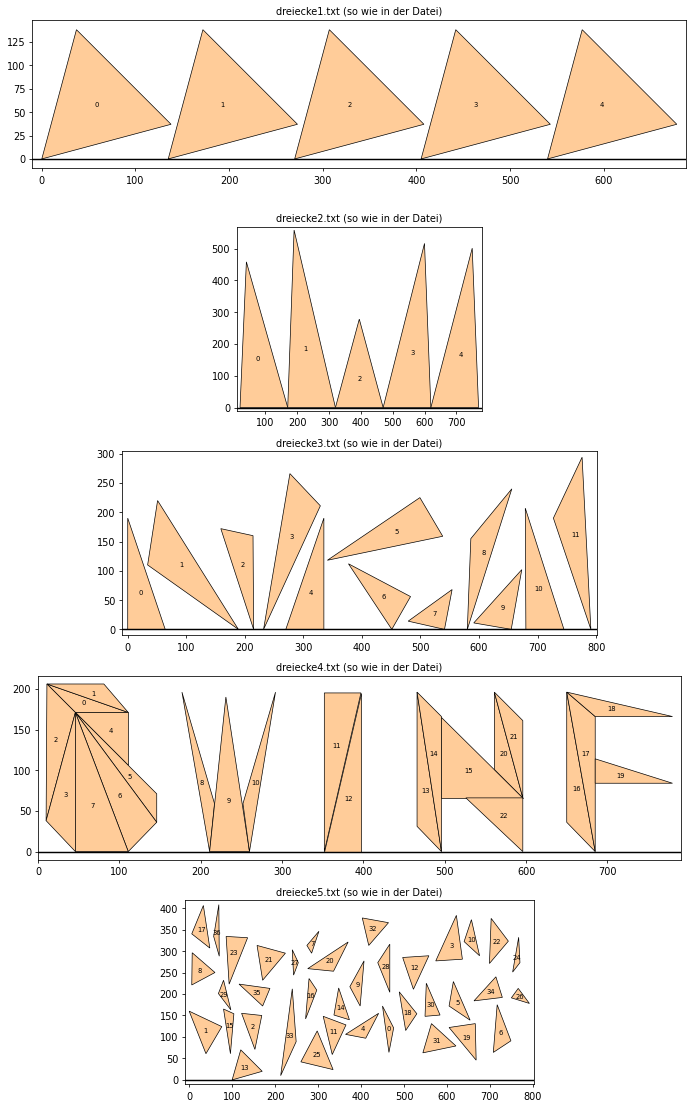

In [ ]:
import math
import os
import random

import matplotlib.pyplot as plt
from matplotlib.patches import Polygon


def datei(nr):
    return os.path.join('beispieldaten', 'dreiecke%d.txt' % nr)


def lies(dateiname):
    with open(dateiname) as f:
        zahlen = f.read().split()
    n = int(zahlen[0])
    dreiecke = []
    pos = 1
    for _ in range(n):
        # zahlen[pos] ist die Zahl der Ecken (immer 3), dann folgen x1 y1 x2 y2 x3 y3
        w = [float(z) for z in zahlen[pos + 1:pos + 7]]
        dreiecke.append([(w[0], w[1]), (w[2], w[3]), (w[4], w[5])])
        pos = pos + 7
    return dreiecke


def schwerpunkt(d):
    return ((d[0][0] + d[1][0] + d[2][0]) / 3, (d[0][1] + d[1][1] + d[2][1]) / 3)


def zeichne(achse, dreiecke, titel, nummern=None):
    for k in range(len(dreiecke)):
        achse.add_patch(Polygon(dreiecke[k], closed=True, facecolor='#ffcc99', edgecolor='black', linewidth=0.7))
        if nummern is not None:
            sx, sy = schwerpunkt(dreiecke[k])
            achse.text(sx, sy, str(nummern[k]), ha='center', va='center', fontsize=7)
    xs = [p[0] for d in dreiecke for p in d]
    ys = [p[1] for d in dreiecke for p in d]
    achse.axhline(0, color='black', linewidth=1.5)          # die Straße
    achse.set_xlim(min(xs) - 10, max(xs) + 10)
    achse.set_ylim(min(ys + [0]) - 10, max(ys) + 10)
    achse.set_aspect('equal')
    achse.set_title(titel, fontsize=10)


beispiele = {}
for nr in range(1, 6):
    beispiele[nr] = lies(datei(nr))
    print('dreiecke%d.txt: %d Dreiecke' % (nr, len(beispiele[nr])))

fig, achsen = plt.subplots(5, 1, figsize=(10, 16))
for nr in range(1, 6):
    zeichne(achsen[nr - 1], beispiele[nr], 'dreiecke%d.txt (so wie in der Datei)' % nr, list(range(len(beispiele[nr]))))
plt.tight_layout()
plt.show()

## Schritt 2: Winkel und Lagen an der Straße

`winkel(d, i)` ist der Innenwinkel des Dreiecks `d` an der Ecke `i` in Grad: Wir bestimmen mit `atan2` die Richtungen der beiden
Kanten, die von der Ecke ausgehen, und nehmen den Unterschied (höchstens 180°). `spitzeste_ecke(d)` gibt die Ecke mit dem kleinsten
Winkel.

`stelle(d, i, gespiegelt, phi)` stellt das Dreieck mit der Ecke `i` in den Ursprung `(0, 0)`. Die erste Kante zeigt in Richtung `phi`,
die zweite in Richtung `phi + w`. Eine Ecke, die `l` vom Ursprung entfernt in Richtung `a` liegt, hat die Koordinaten
`(l · cos a, l · sin a)`. Mit `gespiegelt=True` tauschen die beiden Kanten ihre Rollen; so entsteht das Spiegelbild. Verschieben
nach rechts um `t` macht `schiebe`.

Dreieck 0 aus dreiecke3.txt: [(0.0, 0.0), (64.0, 0.0), (0.0, 190.0)]
  Ecke 0 Winkel 90.00°
  Ecke 1 Winkel 71.38°
  Ecke 2 Winkel 18.62°
  spitzeste Ecke: 2


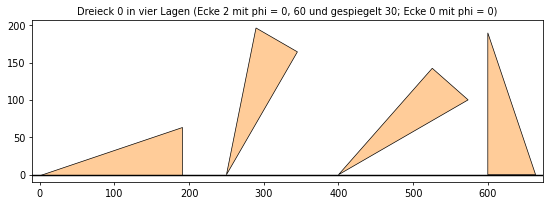

In [ ]:
def laenge(p, q):
    return math.hypot(q[0] - p[0], q[1] - p[1])


def winkel(d, i):
    p = d[i]
    q = d[(i + 1) % 3]
    r = d[(i + 2) % 3]
    a = math.atan2(q[1] - p[1], q[0] - p[0])
    b = math.atan2(r[1] - p[1], r[0] - p[0])
    w = abs(math.degrees(a - b)) % 360
    if w > 180:
        w = 360 - w
    return w


def spitzeste_ecke(d):
    beste = 0
    for i in (1, 2):
        if winkel(d, i) < winkel(d, beste):
            beste = i
    return beste


def stelle(d, i, gespiegelt, phi):
    q = d[(i + 1) % 3]
    r = d[(i + 2) % 3]
    if gespiegelt:
        q, r = r, q
    lq = laenge(d[i], q)
    lr = laenge(d[i], r)
    a = math.radians(phi)
    b = math.radians(phi + winkel(d, i))
    return [(0.0, 0.0), (lq * math.cos(a), lq * math.sin(a)), (lr * math.cos(b), lr * math.sin(b))]


def schiebe(d, t):
    return [(x + t, y) for x, y in d]


d0 = beispiele[3][0]
print('Dreieck 0 aus dreiecke3.txt:', d0)
for i in range(3):
    print('  Ecke', i, 'Winkel %.2f°' % winkel(d0, i))
print('  spitzeste Ecke:', spitzeste_ecke(d0))

lagen0 = [stelle(d0, 2, False, 0), schiebe(stelle(d0, 2, False, 60), 250), schiebe(stelle(d0, 2, True, 30), 400),
          schiebe(stelle(d0, 0, False, 0), 600)]
fig, achse = plt.subplots(figsize=(10, 3))
zeichne(achse, lagen0, 'Dreieck 0 in vier Lagen (Ecke 2 mit phi = 0, 60 und gespiegelt 30; Ecke 0 mit phi = 0)')
plt.show()

Die Winkel ergeben zusammen 180°. Die erste Lage hat die spitzeste Ecke im Ursprung und liegt mit einer Kante auf der Straße, die vierte
steht mit dem rechten Winkel an der Straße.

## Schritt 3: Ein Schiedsrichter

Bevor wir Siedlungen bauen, schreiben wir eine Prüfung, die von unserem Bauverfahren nichts weiß:

- `strassenecken(d)`: die x-Werte der Ecken mit `y = 0` (bis auf eine winzige Toleranz).
- `gesamtabstand(siedlung)`: genau nach der Aufgabe, für jedes Paar von Grundstücken der kleinste Abstand ihrer Straßenecken, davon das
  Größte.
- `ueberlappen(a, b)`: der Trennungssatz. Für jede der sechs Kanten nehmen wir die Richtung senkrecht zu ihr und „projizieren“ beide
  Dreiecke darauf (Skalarprodukt `x · nx + y · ny`). Liegen die beiden Schatten getrennt (oder berühren sich nur), überlappen die
  Dreiecke nicht. Die Toleranz `TOLERANZ = 0.000001` erlaubt Berührungen trotz Rundungsfehlern.
- `pruefe(dreiecke, siedlung, nummern)`: Liegt jedes Dreieck auf der Landseite mit mindestens einer Straßenecke? Hat es dieselben
  Seitenlängen wie in der Datei (nur gedreht, gespiegelt, verschoben)? Kommt jedes Dreieck genau einmal vor? Überlappen sich zwei?

`siedlung` ist die Liste der gelegten Dreiecke, `nummern[k]` sagt, welches Dreieck aus der Datei `siedlung[k]` ist.

In [ ]:
TOLERANZ = 0.000001


def strassenecken(d):
    return [x for x, y in d if abs(y) <= TOLERANZ]


def gesamtabstand(siedlung):
    ecken = [strassenecken(d) for d in siedlung]
    groesster = 0
    for e1 in ecken:
        for e2 in ecken:
            kleinster = min(abs(a - b) for a in e1 for b in e2)
            groesster = max(groesster, kleinster)
    return groesster


def ueberlappen(a, b):
    for d in (a, b):
        for k in range(3):
            p = d[k]
            q = d[(k + 1) % 3]
            nx = q[1] - p[1]                 # Richtung senkrecht zur Kante p-q
            ny = p[0] - q[0]
            l = math.hypot(nx, ny)
            nx = nx / l
            ny = ny / l
            schatten_a = [x * nx + y * ny for x, y in a]
            schatten_b = [x * nx + y * ny for x, y in b]
            if max(schatten_a) <= min(schatten_b) + TOLERANZ or max(schatten_b) <= min(schatten_a) + TOLERANZ:
                return False                 # getrennt: keine Überlappung
    return True


def seiten(d):
    return sorted([laenge(d[0], d[1]), laenge(d[1], d[2]), laenge(d[2], d[0])])


def pruefe(dreiecke, siedlung, nummern):
    if sorted(nummern) != list(range(len(dreiecke))):
        return 'nicht jedes Dreieck genau einmal'
    for k in range(len(siedlung)):
        d = siedlung[k]
        if min(y for x, y in d) < -TOLERANZ:
            return 'Dreieck %d ragt über die Straße' % nummern[k]
        if not strassenecken(d):
            return 'Dreieck %d hat keine Straßenecke' % nummern[k]
        for s1, s2 in zip(seiten(d), seiten(dreiecke[nummern[k]])):
            if abs(s1 - s2) > TOLERANZ:
                return 'Dreieck %d hat andere Seitenlängen' % nummern[k]
    for k in range(len(siedlung)):
        for j in range(k):
            if ueberlappen(siedlung[k], siedlung[j]):
                return 'Dreiecke %d und %d überlappen' % (nummern[j], nummern[k])
    return 'in Ordnung'


for nr in range(1, 6):
    dr = beispiele[nr]
    urteil = pruefe(dr, dr, list(range(len(dr))))
    if urteil == 'in Ordnung':
        print('dreiecke%d.txt so wie in der Datei: in Ordnung, Gesamtabstand %.3f' % (nr, gesamtabstand(dr)))
    else:
        print('dreiecke%d.txt so wie in der Datei: %s' % (nr, urteil))

dreiecke1.txt so wie in der Datei: in Ordnung, Gesamtabstand 540.000
dreiecke2.txt so wie in der Datei: in Ordnung, Gesamtabstand 450.000
dreiecke3.txt so wie in der Datei: Dreieck 5 hat keine Straßenecke
dreiecke4.txt so wie in der Datei: Dreieck 0 hat keine Straßenecke
dreiecke5.txt so wie in der Datei: Dreieck 0 hat keine Straßenecke


Nur die ersten beiden Dateien sind schon eine erlaubte Siedlung, mit großem Gesamtabstand. In den anderen liegen Dreiecke irgendwo im
Koordinatensystem.

## Schritt 4 (Version 1): Ein einziger Fächer

`faecher(dreiecke, nummern, phi0)` legt die Dreiecke mit den angegebenen Nummern mit ihrer spitzesten Ecke um den Ursprung: das erste ab
Richtung `phi0`, jedes weitere gegen den Uhrzeigersinn daneben. Bei jedem Dreieck zeigt die **längere** der beiden Kanten an der
spitzen Ecke in Richtung `phi` (also nach rechts unten im Fächer). Das passt, solange `phi0` plus alle Winkel höchstens 180 ergibt.

Ergeben die spitzesten Winkel **aller** Dreiecke zusammen höchstens 180°, passen alle in einen Fächer, und der Gesamtabstand ist 0.
Wir legen den Fächer mit `phi0 = 180 - Summe` nach links, so dass das letzte Dreieck auf der Straße liegt.

dreiecke1.txt: spitzeste Winkel zusammen 299.9°
dreiecke2.txt: spitzeste Winkel zusammen 96.9°
dreiecke3.txt: spitzeste Winkel zusammen 267.7°
dreiecke4.txt: spitzeste Winkel zusammen 399.3°
dreiecke5.txt: spitzeste Winkel zusammen 1178.2°

Version 1 bei dreiecke2.txt: in Ordnung – Gesamtabstand 0


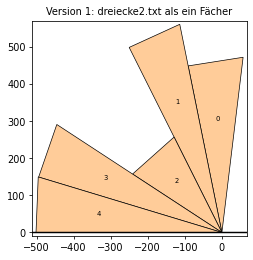

In [ ]:
def faecher(dreiecke, nummern, phi0):
    teile = []
    phi = phi0
    for k in nummern:
        d = dreiecke[k]
        i = spitzeste_ecke(d)
        gespiegelt = laenge(d[i], d[(i + 1) % 3]) < laenge(d[i], d[(i + 2) % 3])   # längere Kante zuerst
        teile.append(stelle(d, i, gespiegelt, phi))
        phi = phi + winkel(d, i)
    return teile


def spitz_summe(dreiecke, nummern):
    summe = 0
    for k in nummern:
        summe = summe + winkel(dreiecke[k], spitzeste_ecke(dreiecke[k]))
    return summe


for nr in range(1, 6):
    dr = beispiele[nr]
    print('dreiecke%d.txt: spitzeste Winkel zusammen %.1f°' % (nr, spitz_summe(dr, range(len(dr)))))

dr2 = beispiele[2]
alle2 = list(range(len(dr2)))
siedlung_v1 = faecher(dr2, alle2, 180 - spitz_summe(dr2, alle2))
print()
print('Version 1 bei dreiecke2.txt:', pruefe(dr2, siedlung_v1, alle2), '– Gesamtabstand', gesamtabstand(siedlung_v1))
fig, achse = plt.subplots(figsize=(8, 4))
zeichne(achse, siedlung_v1, 'Version 1: dreiecke2.txt als ein Fächer', alle2)
plt.show()

Bei `dreiecke2.txt` ist das schon die beste Lösung: Gesamtabstand 0, wie in den Lösungshinweisen. Bei allen anderen Beispielen sind die
spitzesten Winkel zusammen größer als 180°; dort braucht man mehrere Fächer oder andere Ideen.

## Schritt 5: Anschieben

Ein neues Dreieck `b` (in fester Lage, mit seiner Straßenecke im Ursprung) soll von rechts an ein altes Dreieck `a` geschoben werden.
Auf einer Höhe `y` schneidet die waagerechte Gerade jedes Dreieck in einer Strecke von `links` bis `rechts` (`sehne`). Nach dem
Verschieben um `t` liegt `b` rechts von `a`, wenn auf **jeder** gemeinsamen Höhe `links_b(y) + t ≥ rechts_a(y)` gilt. Das kleinste
solche `t` ist also das **größte** `rechts_a(y) - links_b(y)` über alle gemeinsamen Höhen.

Man muss dafür nicht alle Höhen durchgehen: Zwischen zwei Eckhöhen ändern sich beide Ränder gleichmäßig (linear), der Unterschied also
auch. Das Größte liegt deshalb an der unteren oder oberen Grenze des gemeinsamen Höhenbereichs oder auf der Höhe einer Ecke. Teilen
sich die beiden Dreiecke keine Höhe (oder nur eine einzige), können sie sich nicht im Weg sein; dann gibt `abstand_rechts` `None`
zurück.

`verschiebung(siedlung, b)` ist das größte `t` über alle alten Dreiecke: So weit nach links kommt `b`, dann berührt es das erste.
`aufrufe` zählt, wie oft `abstand_rechts` rechnet.

Verschiebung: 142.874
Überlappen nach dem Verschieben? False
Und 0,1 weiter links? True


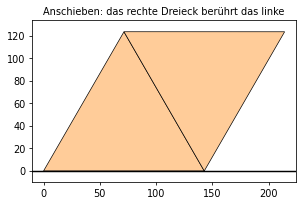

In [ ]:
aufrufe = 0


def sehne(d, y):
    xs = []
    for k in range(3):
        p = d[k]
        q = d[(k + 1) % 3]
        if abs(p[1] - y) <= 1e-9:
            xs.append(p[0])                                    # Ecke genau auf dieser Höhe
        if (p[1] - y) * (q[1] - y) < 0:                        # Kante kreuzt die Höhe y
            xs.append(p[0] + (y - p[1]) * (q[0] - p[0]) / (q[1] - p[1]))
    return min(xs), max(xs)


def abstand_rechts(a, b):
    global aufrufe
    aufrufe = aufrufe + 1
    unten = max(min(p[1] for p in a), min(p[1] for p in b))
    oben = min(max(p[1] for p in a), max(p[1] for p in b))
    if oben - unten <= 1e-9:
        return None
    hoehen = [unten, oben]
    for p in a + b:
        if unten < p[1] < oben:
            hoehen.append(p[1])
    groesster = None
    for y in hoehen:
        t = sehne(a, y)[1] - sehne(b, y)[0]
        if groesster is None or t > groesster:
            groesster = t
    return groesster


def verschiebung(siedlung, b):
    t = None
    for a in siedlung:
        s = abstand_rechts(a, b)
        if s is not None and (t is None or s > t):
            t = s
    if t is None:
        t = 0.0
    return t


dr1 = beispiele[1]
a1 = stelle(dr1[0], 0, False, 0)                 # liegt flach rechts vom Ursprung
b1 = stelle(dr1[1], 0, True, 60)                 # steht auf seiner Spitze
t1 = verschiebung([a1], b1)
print('Verschiebung: %.3f' % t1)
print('Überlappen nach dem Verschieben?', ueberlappen(a1, schiebe(b1, t1)))
print('Und 0,1 weiter links?', ueberlappen(a1, schiebe(b1, t1 - 0.1)))
fig, achse = plt.subplots(figsize=(6, 3))
zeichne(achse, [a1, schiebe(b1, t1)], 'Anschieben: das rechte Dreieck berührt das linke')
plt.show()

Das umgedrehte Dreieck rutscht nach links, bis seine linke Kante an der rechten Kante des flachen Dreiecks anliegt; seine Spitze steht
dann genau auf dessen rechter Ecke. Der Schiedsrichter bestätigt: genau dort keine Überlappung, ein kleines Stück weiter links schon.

## Schritt 6 (Version 2): Fächer nebeneinander

Die naheliegende Erweiterung von Version 1: Wir sortieren die Dreiecke nach ihrem spitzesten Winkel und füllen damit nacheinander
Fächer, bis die nächste Ecke nicht mehr hineinpasst (Summe über 180°). Dann legen wir die Fächer von links nach rechts:

- den ersten nach links gelehnt (`phi0 = 180 - Summe`, die letzte Kante liegt links auf der Straße),
- den letzten nach rechts gelehnt (`phi0 = 0`),
- jeden mittleren in jedem Winkel `phi0` von 0 bis `180 - Summe` in Schritten von 1°; wir nehmen den, der sich am weitesten nach links
  schieben lässt.

Einen ganzen Fächer schieben wir an, indem wir das größte `verschiebung` seiner Dreiecke nehmen (`fuege_an`).

dreiecke1.txt: 2 Fächer, Gesamtabstand  142.951, in Ordnung
dreiecke2.txt: 1 Fächer, Gesamtabstand    0.000, in Ordnung
dreiecke3.txt: 2 Fächer, Gesamtabstand  245.166, in Ordnung
dreiecke4.txt: 3 Fächer, Gesamtabstand  422.929, in Ordnung
dreiecke5.txt: 8 Fächer, Gesamtabstand 1108.371, in Ordnung


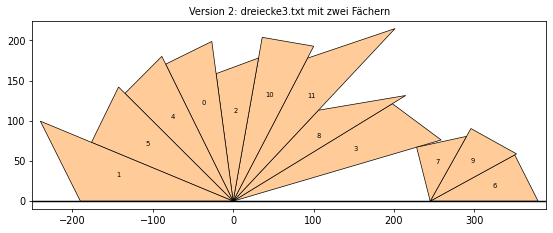

In [ ]:
def fuege_an(siedlung, teile):
    if not siedlung:
        return 0.0
    t = None
    for d in teile:
        s = verschiebung(siedlung, d)
        if t is None or s > t:
            t = s
    return t


def faecher_einteilen(dreiecke):
    paare = sorted([(winkel(dreiecke[k], spitzeste_ecke(dreiecke[k])), k) for k in range(len(dreiecke))])
    liste = [[]]
    summe = 0
    for w, k in paare:
        if summe + w > 180:
            liste.append([])
            summe = 0
        liste[-1].append(k)
        summe = summe + w
    return liste


def faecher_nebeneinander(dreiecke, faecherliste):
    siedlung = []
    nummern = []
    for f in range(len(faecherliste)):
        frei = 180 - spitz_summe(dreiecke, faecherliste[f])
        if f == 0:
            versuche = [frei]
        elif f == len(faecherliste) - 1:
            versuche = [0]
        else:
            versuche = list(range(0, int(frei) + 1)) + [frei]
        bester = None
        for phi0 in versuche:
            teile = faecher(dreiecke, faecherliste[f], phi0)
            t = fuege_an(siedlung, teile)
            if bester is None or t < bester[0]:
                bester = (t, teile)
        t, teile = bester
        for d in teile:
            siedlung.append(schiebe(d, t))
        nummern = nummern + faecherliste[f]
    return siedlung, nummern


ergebnis_v2 = {}
for nr in range(1, 6):
    dr = beispiele[nr]
    fl = faecher_einteilen(dr)
    siedlung, nummern = faecher_nebeneinander(dr, fl)
    ergebnis_v2[nr] = (len(fl), gesamtabstand(siedlung))
    print('dreiecke%d.txt: %d Fächer, Gesamtabstand %8.3f, %s' % (nr, len(fl), gesamtabstand(siedlung),
                                                                pruefe(dr, siedlung, nummern)))
    if nr == 3:
        siedlung_v2_3, nummern_v2_3 = siedlung, nummern

fig, achse = plt.subplots(figsize=(10, 3.5))
zeichne(achse, siedlung_v2_3, 'Version 2: dreiecke3.txt mit zwei Fächern', nummern_v2_3)
plt.show()

Alle Siedlungen sind erlaubt, aber lang: Die Lösungshinweise kommen bei `dreiecke3.txt` auf 74,911, wir auf etwa das Dreifache. Das
Bild zeigt, warum: Der erste Fächer ist fast voll, seine letzten Dreiecke liegen deshalb flach nach rechts und ragen weit hinaus. Erst
dahinter hat der zweite Fächer Platz. Die Bewertungshinweise geben für eine solche einfache Fächeranordnung ohne Verbesserungen Minuspunkte.

## Schritt 7 (Version 3): Gierig nach dem Schwerpunkt

Jetzt bauen wir die Siedlung **Dreieck für Dreieck** von links nach rechts (Lösungshinweise, Abschnitt 2.1). Für jedes Dreieck legen
wir vorab alle Lagen an: jede Ecke an die Straße, beide Seiten, Drehwinkel `phi` von 0 bis `180 - w` in Schritten von `schritt` Grad
und dazu genau `180 - w` (`alle_stellungen`). In jedem Schritt schieben wir jedes übrige Dreieck in jeder Lage an die Siedlung und
nehmen das, dessen **Schwerpunkt** danach am weitesten links liegt.

Das sind viele Versuche: bei `dreiecke5.txt` am Anfang 37 Dreiecke mit je über 700 Lagen. Zwei Abkürzungen in `bester_anbau` machen es
schnell genug, ohne das Ergebnis zu ändern:

1. Die alten Dreiecke werden nach ihrem rechten Ende sortiert, das rechteste zuerst. Ein altes Dreieck `a` kann das neue höchstens bis
   `rechtes Ende von a - linkes Ende von b` aufhalten. Ist das nicht mehr als die schon gefundene Verschiebung, kann kein weiteres
   Dreieck mehr etwas ändern: abbrechen.
2. Die Verschiebung wächst beim Durchgehen nur. Liegt der Schwerpunkt schon jetzt nicht links vom besten bisher, ist diese Lage
   verloren: abbrechen.

dreiecke1.txt: Gesamtabstand  142.887, in Ordnung, abstand_rechts    2480-mal (ohne Abkürzungen     4960-mal)
dreiecke2.txt: Gesamtabstand    4.762, in Ordnung, abstand_rechts    2562-mal (ohne Abkürzungen     4980-mal)
dreiecke3.txt: Gesamtabstand  162.977, in Ordnung, abstand_rechts   16751-mal (ohne Abkürzungen    71296-mal)
dreiecke4.txt: Gesamtabstand  323.374, in Ordnung, abstand_rechts   63902-mal (ohne Abkürzungen   505976-mal)
dreiecke5.txt: Gesamtabstand  725.175, in Ordnung, abstand_rechts  166288-mal (ohne Abkürzungen  2096932-mal)


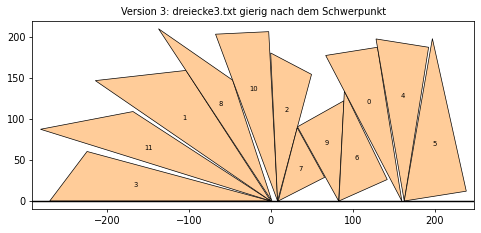

In [ ]:
def alle_stellungen(d, schritt):
    lagen = []
    for i in range(3):
        frei = 180 - winkel(d, i)
        drehungen = list(range(0, int(frei) + 1, schritt)) + [frei]
        for gespiegelt in (False, True):
            for phi in drehungen:
                lagen.append(stelle(d, i, gespiegelt, phi))
    return lagen


def bester_anbau(siedlung, kandidaten, lagen):
    rechts = []
    for a in siedlung:
        rechts.append((max(a[0][0], a[1][0], a[2][0]), a))
    rechts.sort(reverse=True)                 # rechtestes Dreieck zuerst
    bester = None                             # (Schwerpunkt-x, Nummer, geschobenes Dreieck)
    for k in kandidaten:
        for d in lagen[k]:
            sx = schwerpunkt(d)[0]
            links = min(d[0][0], d[1][0], d[2][0])
            t = None
            verloren = False
            for rechtes_ende, a in rechts:
                if t is not None and rechtes_ende - links <= t:
                    break                                       # Abkürzung 1
                s = abstand_rechts(a, d)
                if s is not None and (t is None or s > t):
                    t = s
                    if bester is not None and sx + t >= bester[0]:
                        verloren = True                         # Abkürzung 2
                        break
            if verloren:
                continue
            if t is None:
                t = 0.0                                         # das erste Dreieck
            if bester is None or sx + t < bester[0]:
                bester = (sx + t, k, schiebe(d, t))
    return bester[1], bester[2]


def gierig(dreiecke, schritt):
    lagen = [alle_stellungen(d, schritt) for d in dreiecke]
    rest = list(range(len(dreiecke)))
    siedlung = []
    nummern = []
    while rest:
        k, d = bester_anbau(siedlung, rest, lagen)
        siedlung.append(d)
        nummern.append(k)
        rest.remove(k)
    return siedlung, nummern


ergebnis_v3 = {}
for nr in range(1, 6):
    dr = beispiele[nr]
    aufrufe = 0
    siedlung, nummern = gierig(dr, 3)
    # so oft hätte abstand_rechts ohne Abkürzungen rechnen müssen:
    lagenzahl = [len(alle_stellungen(d, 3)) for d in dr]
    ohne = 0
    for j in range(len(dr)):
        ohne = ohne + j * sum(lagenzahl[k] for k in nummern[j:])
    ergebnis_v3[nr] = (gesamtabstand(siedlung), aufrufe, ohne)
    text = 'dreiecke%d.txt: Gesamtabstand %8.3f, %s, abstand_rechts %7d-mal (ohne Abkürzungen %8d-mal)'
    print(text % (nr, gesamtabstand(siedlung), pruefe(dr, siedlung, nummern), aufrufe, ohne))
    if nr == 3:
        siedlung_v3_3, nummern_v3_3 = siedlung, nummern

fig, achse = plt.subplots(figsize=(10, 3.5))
zeichne(achse, siedlung_v3_3, 'Version 3: dreiecke3.txt gierig nach dem Schwerpunkt', nummern_v3_3)
plt.show()

Die Abkürzungen sparen viel: Bei `dreiecke5.txt` rechnet `abstand_rechts` etwa 12-mal seltener, bei `dreiecke4.txt` etwa 8-mal. Die Ergebnisse sind bei den großen
Beispielen viel besser als mit Version 2; bei `dreiecke5.txt` (725,175) liegen wir fast genau beim deterministischen Wert der
Lösungshinweise (724). Bei `dreiecke2.txt` ist Version 3 aber schlechter als ein einziger Fächer, und bei `dreiecke3.txt` (162,977)
weit weg von 74,911. Das Bild zeigt den Grund: Die Dreiecke treffen sich an drei Punkten der Straße statt an zwei, und am rechten
Rand stehen sie steil, obwohl dort Platz für flach liegende wäre.

## Schritt 8 (Version 4): Starter und Stopper

Die Lösungshinweise (Abschnitt 2.1.7) legen deshalb an beide Enden einen Fächer:

- **Starter:** Passen alle spitzesten Winkel in 180°, kommen alle Dreiecke in einen Fächer (Version 1). Sonst nehmen wir die Dreiecke,
  deren Schwerpunkt am weitesten von der spitzesten Ecke entfernt ist (lange, schmale Dreiecke), so lange, bis ihre Winkel zusammen
  mehr als 90° ergeben. Der Fächer lehnt nach links, die rechte Wand steht dann ungefähr senkrecht.
- Danach geht es **gierig** weiter wie in Version 3.
- **Stopper:** Vor jedem gierigen Schritt prüfen wir: Passen alle übrigen Dreiecke in einen Fächer? Dann probieren wir ihn mit `phi0`
  von 0 bis `180 - Summe` in Schritten von 5° als Abschluss aus und merken uns, wie lang die Siedlung damit würde. Danach bauen wir
  gierig weiter. Am Ende nehmen wir die kürzeste Siedlung, die wir unterwegs gesehen haben (auch die ganz gierige ohne Stopper).

Der Parameter `zufall` kommt erst in Version 5 dran.

dreiecke1.txt: Gesamtabstand  142.836, in Ordnung
dreiecke2.txt: Gesamtabstand    0.000, in Ordnung
dreiecke3.txt: Gesamtabstand   74.911, in Ordnung
dreiecke4.txt: Gesamtabstand  203.815, in Ordnung
dreiecke5.txt: Gesamtabstand  711.874, in Ordnung


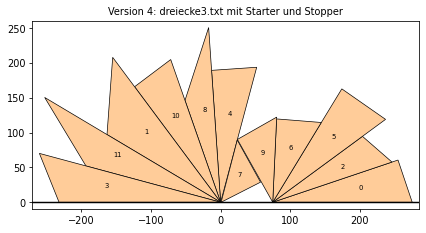

In [ ]:
def starter_waehlen(dreiecke):
    alle = list(range(len(dreiecke)))
    if spitz_summe(dreiecke, alle) <= 180:
        return alle
    paare = []
    for k in alle:
        d = dreiecke[k]
        paare.append((laenge(d[spitzeste_ecke(d)], schwerpunkt(d)), k))
    paare.sort(reverse=True)
    starter = []
    for abstand, k in paare:
        starter.append(k)
        if spitz_summe(dreiecke, starter) > 90:
            break
    return starter


def stopper_versuchen(dreiecke, siedlung, nummern, rest, bester):
    frei = 180 - spitz_summe(dreiecke, rest)
    if frei < 0:
        return bester                                   # passt nicht in einen Fächer
    for phi0 in list(range(0, int(frei) + 1, 5)) + [frei]:
        teile = faecher(dreiecke, rest, phi0)
        t = fuege_an(siedlung, teile)
        ganz = siedlung + [schiebe(d, t) for d in teile]
        g = gesamtabstand(ganz)
        if bester is None or g < bester[0]:
            bester = (g, ganz, nummern + rest)
    return bester


def siedlung_bauen(dreiecke, schritt, zufall=None):
    starter = starter_waehlen(dreiecke)
    starter.reverse()                                   # das längste Dreieck ganz links an die Straße
    siedlung = faecher(dreiecke, starter, 180 - spitz_summe(dreiecke, starter))
    nummern = starter[:]
    rest = [k for k in range(len(dreiecke)) if k not in starter]
    lagen = {}
    for k in rest:
        lagen[k] = alle_stellungen(dreiecke[k], schritt)
    bester = None                                       # (Gesamtabstand, Siedlung, Nummern)
    while rest:
        bester = stopper_versuchen(dreiecke, siedlung, nummern, rest, bester)
        kandidaten = rest
        if zufall is not None and len(rest) > 1:        # Version 5: jedes Dreieck nur mit Wahrscheinlichkeit 1/2
            kandidaten = [k for k in rest if zufall.random() < 0.5]
            if not kandidaten:
                kandidaten = [zufall.choice(rest)]
        k, d = bester_anbau(siedlung, kandidaten, lagen)
        siedlung = siedlung + [d]
        nummern = nummern + [k]
        rest.remove(k)
    g = gesamtabstand(siedlung)
    if bester is None or g < bester[0]:
        bester = (g, siedlung, nummern)
    return bester


ergebnis_v4 = {}
for nr in range(1, 6):
    dr = beispiele[nr]
    g, siedlung, nummern = siedlung_bauen(dr, 3)
    ergebnis_v4[nr] = (g, siedlung, nummern)
    print('dreiecke%d.txt: Gesamtabstand %8.3f, %s' % (nr, g, pruefe(dr, siedlung, nummern)))

fig, achse = plt.subplots(figsize=(10, 3.5))
zeichne(achse, ergebnis_v4[3][1], 'Version 4: dreiecke3.txt mit Starter und Stopper', ergebnis_v4[3][2])
plt.show()

Das bringt viel: `dreiecke3.txt` hat jetzt genau den Gesamtabstand 74,911 der Lösungshinweise, und wie dort stehen die Dreiecke in zwei
Fächern bei 0 und bei 74,911; nur Dreieck 7 ist gierig in die Lücke dazwischen gelegt. `dreiecke1.txt` (142,836) und `dreiecke2.txt` (0) stimmen ebenfalls mit den Hinweisen überein (dort 142,83 und 0).
Bei `dreiecke4.txt` sind wir mit 203,815 besser als der schnelle Wert der Hinweise (224), bei `dreiecke5.txt` mit 711,874 knapp besser als
724.

## Schritt 9 (Version 5): Zufall

Das gierige Verfahren entscheidet immer nur nach dem nächsten Schritt; eine Wahl, die jetzt gut aussieht, kann später schaden. Die
Lösungshinweise (Abschnitt 2.1.9) lassen deshalb in jedem Schritt jedes Dreieck mit Wahrscheinlichkeit 1/2 weg. So entstehen
verschiedene Siedlungen, und wir behalten die kürzeste. Wir bauen 20 solche Siedlungen zusätzlich zu der aus Version 4. Mit
`random.Random(1)` kommen bei jedem Lauf des Notebooks dieselben Zufallszahlen heraus.

In [ ]:
LAEUFE = 20
ergebnis_v5 = {}
for nr in range(1, 6):
    dr = beispiele[nr]
    zufall = random.Random(1)
    bester = ergebnis_v4[nr]
    verbessert = 0
    for lauf in range(LAEUFE):
        neu = siedlung_bauen(dr, 3, zufall)
        if neu[0] < bester[0]:
            bester = neu
            verbessert = verbessert + 1
    ergebnis_v5[nr] = bester
    print('dreiecke%d.txt: Gesamtabstand %8.3f (%d-mal verbessert), %s' % (nr, bester[0], verbessert,
                                                                         pruefe(dr, bester[1], bester[2])))

dreiecke1.txt: Gesamtabstand  142.836 (0-mal verbessert), in Ordnung
dreiecke2.txt: Gesamtabstand    0.000 (0-mal verbessert), in Ordnung
dreiecke3.txt: Gesamtabstand   74.911 (0-mal verbessert), in Ordnung
dreiecke4.txt: Gesamtabstand  203.815 (0-mal verbessert), in Ordnung
dreiecke5.txt: Gesamtabstand  688.228 (2-mal verbessert), in Ordnung


Nur bei `dreiecke5.txt` hilft der Zufall (von 711,874 auf 688,228); bei den anderen Beispielen findet er in 20 Läufen nichts Besseres
als Version 4. Die
Lösungshinweise erzeugen mit einem schnelleren Programm etwa 1000 Siedlungen pro Sekunde und kommen damit weiter (Laufzeiten aus den
Hinweisen):

| Beispiel | Hinweise | Version 2 | Version 3 | Version 4 | Version 5 |
|----------|----------|-----------|-----------|-----------|-----------|
| `dreiecke1.txt` | 142,83 | 142,951 | 142,887 | 142,836 | 142,836 |
| `dreiecke2.txt` | 0 | 0 | 4,762 | 0 | 0 |
| `dreiecke3.txt` | 74,911 | 245,166 | 162,977 | 74,911 | 74,911 |
| `dreiecke4.txt` | 224 (0,05 s), 174 (1 s), 171,050 (etwa 2 h) | 422,929 | 323,374 | 203,815 | 203,815 |
| `dreiecke5.txt` | 724 (0,15 s), 660 (1 s), 650 (5 s), 630,741 (etwa 2 h) | 1108,371 | 725,175 | 711,874 | 688,228 |

Bei den beiden großen Beispielen sind wir also besser als die schnellen deterministischen Werte der Hinweise, aber deutlich schlechter
als ihre Ergebnisse nach einer Sekunde Zufallssuche. Bei `dreiecke4.txt` fehlen uns etwa 33 Meter (19 %) zum besten bekannten Wert, bei
`dreiecke5.txt` etwa 57 Meter (9 %). Ob 171,050 und 630,741 die besten möglichen Werte sind, weiß niemand.

## Schritt 10: Die Ergebnisse

(a) Die Zeichnungen der besten gefundenen Siedlungen (Version 5) mit den Nummern der Dreiecke:

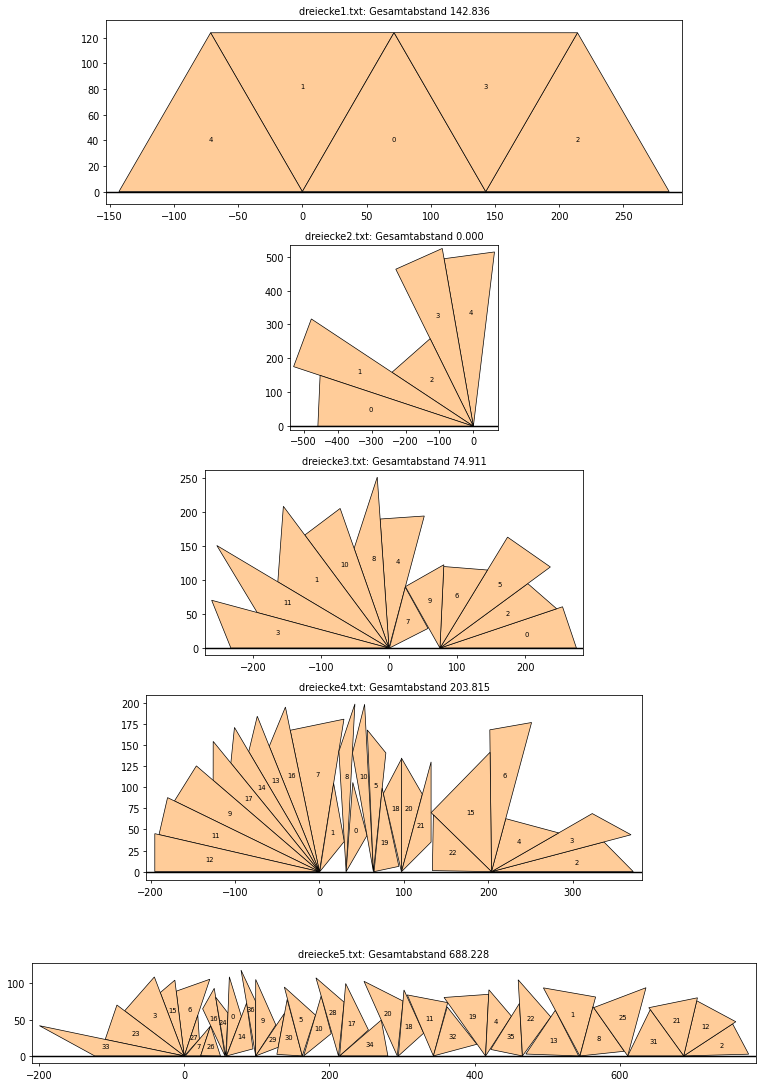

In [ ]:
fig, achsen = plt.subplots(5, 1, figsize=(11, 16))
for nr in range(1, 6):
    g, siedlung, nummern = ergebnis_v5[nr]
    zeichne(achsen[nr - 1], siedlung, 'dreiecke%d.txt: Gesamtabstand %.3f' % (nr, g), nummern)
plt.tight_layout()
plt.show()

(b) Die Folge der Dreiecke, sortiert nach ihrer Lage an der x-Achse: zuerst nach der linkesten Straßenecke, bei gleicher Straßenecke nach
dem Schwerpunkt. Koordinaten auf zwei Stellen gerundet (das erlauben die Bewertungshinweise). Bei den großen Beispielen zeigen wir nur
den Anfang.

In [ ]:
def zahl(x):
    return '%.2f' % (round(x, 2) + 0.0)          # + 0.0 macht aus -0.0 eine 0.0


def folge(siedlung, nummern):
    paare = []
    for k in range(len(siedlung)):
        d = siedlung[k]
        paare.append((min(strassenecken(d)), schwerpunkt(d)[0], nummern[k], d))
    paare.sort()
    zeilen = []
    for ecke, sx, nummer, d in paare:
        zeilen.append('ID%-2d ' % nummer + ' '.join(zahl(p[0]) + ' ' + zahl(p[1]) for p in d))
    return zeilen


for nr in range(1, 6):
    g, siedlung, nummern = ergebnis_v5[nr]
    zeilen = folge(siedlung, nummern)
    print('dreiecke%d.txt: Gesamtabstand %.3f' % (nr, g))
    if len(zeilen) <= 12:
        print('\n'.join(zeilen))
    else:
        print('\n'.join(zeilen[:5]))
        print('... (%d weitere Dreiecke)' % (len(zeilen) - 5))
    print()

dreiecke1.txt: Gesamtabstand 142.836
ID4  0.00 0.00 -71.48 123.71 -142.87 0.00
ID1  0.00 0.00 71.36 123.78 -71.48 123.71
ID0  142.84 0.00 71.42 123.74 0.00 0.00
ID3  142.84 0.00 214.31 123.71 71.48 123.78
ID2  142.84 0.00 285.71 0.00 214.31 123.71

dreiecke2.txt: Gesamtabstand 0.000
ID0  0.00 0.00 -451.89 149.86 -458.44 0.00
ID1  0.00 0.00 -477.69 316.34 -529.98 175.75
ID2  0.00 0.00 -127.53 258.16 -240.07 158.98
ID3  0.00 0.00 -91.76 524.15 -228.72 462.97
ID4  0.00 0.00 62.21 513.84 -86.46 493.89

dreiecke3.txt: Gesamtabstand 74.911
ID3  0.00 0.00 -260.48 70.22 -232.23 0.00
ID11 0.00 0.00 -252.91 150.66 -193.58 52.18
ID1  0.00 0.00 -155.13 208.28 -163.29 97.27
ID10 0.00 0.00 -71.71 205.09 -123.65 166.01
ID8  0.00 0.00 -17.20 251.16 -51.20 146.42
ID4  0.00 0.00 51.87 194.00 -12.98 189.56
ID7  0.75 0.00 57.38 28.86 23.92 89.47
ID9  74.91 0.00 80.59 122.36 24.14 90.28
ID6  74.91 0.00 144.77 114.63 80.47 119.75
ID5  74.91 0.00 237.10 119.10 174.21 162.95
ID2  74.91 0.00 246.33 57.74 203.8

## Für Neugierige: Feinere Drehwinkel?

Wir haben die Drehwinkel in Schritten von 3° probiert. Man könnte meinen, kleinere Schritte geben immer bessere Siedlungen. Bei einem
gierigen Verfahren stimmt das nicht: Eine im Moment etwas bessere Lage kann später schaden. Version 4 mit Schritten von 1°, 3° und 5°:

In [ ]:
schritte_vergleich = {}
for nr in (4, 5):
    werte = []
    for schritt in (1, 3, 5):
        werte.append(siedlung_bauen(beispiele[nr], schritt)[0])
    schritte_vergleich[nr] = werte
    print('dreiecke%d.txt: 1° %.3f   3° %.3f   5° %.3f' % (nr, werte[0], werte[1], werte[2]))

dreiecke4.txt: 1° 225.006   3° 203.815   5° 215.070
dreiecke5.txt: 1° 713.558   3° 711.874   5° 735.536


Bei `dreiecke4.txt` ist der feinste Schritt sogar der schlechteste, bei `dreiecke5.txt` der gröbste. Dass 3° bei beiden am besten
abschneidet, ist Glück und keine Regel: Schon ein anderes Beispiel kann es umgekehrt zeigen.

**Grenzen unseres Verfahrens.** Ein Dreieck wird nur von rechts angeschoben; in eine Höhle weiter links, an die man nur „von oben“
käme, gelangt es nie. Das Schwerpunkt-Kriterium schaut nur einen Schritt voraus. Starter und Stopper sind einfache Fächer; die
Hinweise schreiben selbst, dass man sie weiter verbessern könnte. Und unser Python-Programm ist viel langsamer als das der Hinweise,
darum probieren wir nur wenige Zufallsläufe. Mehr Läufe oder eine nachträgliche Verbesserung (zum Beispiel zwei Dreiecke tauschen und
neu anschieben) wären die nächsten Schritte.

## Zum Schluss: Fächer mit MiniZinc

Die ganze Aufgabe passt nicht gut zu MiniZinc: Die Lagen sind Kommazahlen, Drehungen brauchen `sin` und `cos`, und „zwei gedrehte
Dreiecke überlappen sich nicht“ ist eine schwierige Bedingung zwischen allen Paaren. Ein **Teilproblem** dagegen ist eine typische
Zuordnungsaufgabe: In Version 2 haben wir die Dreiecke einfach der Reihe nach auf Fächer verteilt. Wie viele Fächer braucht man
**mindestens**, wenn in jedem die spitzesten Winkel zusammen höchstens 180° ergeben dürfen? (Das ist das bekannte **Behälterproblem**,
englisch *bin packing*.)

MiniZinc rechnet hier mit ganzen Zahlen. Wir rechnen die Winkel in Hundertstel Grad um und runden **auf**: Was mit den aufgerundeten
Winkeln in 18000 passt, passt auch mit den echten in 180°.

- `fach[i]` ist der Fächer von Dreieck `i`, `anzahl` die Zahl der benutzten Fächer.
- `w[i] * (fach[i] = f)`: Der Vergleich `fach[i] = f` ist wahr oder falsch; in einer Rechnung zählt wahr als 1 und falsch als 0. Die
  Summe ist also die Winkelsumme in Fächer `f`.
- Die beiden Bedingungen zum **Symmetriebrechen** verbieten Lösungen, die sich nur in der Nummerierung der Fächer unterscheiden
  (`max(fach[1..i-1])` ist die größte Fächernummer unter den ersten `i - 1` Dreiecken).
- Die letzte Bedingung folgt eigentlich aus den anderen. Sie hilft dem Solver aber zu **beweisen**, dass es nicht mit weniger Fächern
  geht.
```minizinc
int: n;                                   % Zahl der Dreiecke
array[1..n] of int: w;                    % spitzester Winkel in Hundertstel Grad (aufgerundet)

array[1..n] of var 1..n: fach;            % in welchen Fächer kommt Dreieck i?
var 1..n: anzahl;                         % so viele Fächer werden gebraucht

constraint forall(i in 1..n)(fach[i] <= anzahl);
constraint forall(f in 1..n)(sum(i in 1..n)(w[i] * (fach[i] = f)) <= 18000);

% Symmetrie brechen: Dreieck 1 in Fächer 1, jedes weitere höchstens in einen neuen Fächer
constraint fach[1] = 1;
constraint forall(i in 2..n)(fach[i] <= max(fach[1..i-1]) + 1);

% zusätzliches Wissen: alle Winkel zusammen müssen in die Fächer passen
constraint anzahl * 18000 >= sum(w);

solve minimize anzahl;
output ["anzahl = \(anzahl)\nfach = \(fach)\n"];
```

Die Datendatei erzeugt `als_dzn`:

In [ ]:
def als_dzn(dreiecke):
    w = [math.ceil(winkel(d, spitzeste_ecke(d)) * 100) for d in dreiecke]
    return 'n = %d;\nw = %s;' % (len(dreiecke), w)


print(als_dzn(beispiele[1]))

n = 5;
w = [5999, 5999, 5999, 5999, 5999];


**`dreiecke5.txt`** (Gecode):

**Ausgabe:**

```
anzahl = 7
fach = [1, 1, 1, 1, 1, 2, 2, 1, 2, 2, 2, 3, 3, 3, 3, 2, 4, 4, 4, 4, 4, 5, 5, 4, 5, 5, 6, 5, 6, 6, 6, 6, 7, 6, 7, 7, 3]
----------
==========
```

`==========` heißt: Die Lösung ist bewiesen optimal. So sieht es bei allen Beispielen aus (gemessen beim Erstellen dieses Notebooks mit
Zeitlimit 60 Sekunden, einmal mit und einmal ohne die letzte Bedingung):

| Beispiel | wenigste Fächer | Version 2 | mit der letzten Bedingung | ohne sie |
|----------|-----------------|-----------|---------------------------|----------|
| `dreiecke1.txt` | 2 | 2 | alle Solver sofort | alle Solver sofort |
| `dreiecke2.txt` | 1 | 1 | alle Solver sofort | alle Solver sofort |
| `dreiecke3.txt` | 2 | 2 | alle Solver sofort | alle Solver sofort |
| `dreiecke4.txt` | 3 | 3 | alle Solver sofort | alle Solver sofort |
| `dreiecke5.txt` | 7 | 8 | alle Solver in unter 1 Sekunde | Gecode und Chuffed finden 7 Fächer, beweisen aber in 60 Sekunden nicht, dass es nicht mit 6 geht; CP-SAT beweist es in unter 1 Sekunde |

Ohne die letzte Bedingung müssten Gecode und Chuffed alle Verteilungen auf 6 Fächer ausschließen, und davon gibt es sehr viele.
Die Bedingung `anzahl * 18000 >= sum(w)` sagt ihnen sofort: 6 Fächer fassen höchstens 1080°, die Winkel ergeben aber über 1178°.
CP-SAT kommt von selbst auf solche Schranken.

Nur bei `dreiecke5.txt` ist unsere einfache Verteilung schlechter als nötig. Bringen 7 Fächer statt 8 eine kürzere Siedlung? Wir
übernehmen die Verteilung von MiniZinc in Version 2 (`fach` mit Fächern ab 1, Dreiecke ab 0):

In [ ]:
fach5 = [1, 1, 1, 1, 1, 2, 2, 1, 2, 2, 2, 3, 3, 3, 3, 2, 4, 4, 4, 4, 4, 5, 5, 4, 5, 5, 6, 5, 6, 6, 6, 6, 7, 6, 7, 7, 3]

dr5 = beispiele[5]
anzahl5 = max(fach5)
faecher_mz = []
for f in range(1, anzahl5 + 1):
    faecher_mz.append([k for k in range(len(dr5)) if fach5[k] == f])
siedlung_mz, nummern_mz = faecher_nebeneinander(dr5, faecher_mz)
g_mz = gesamtabstand(siedlung_mz)
print('dreiecke5.txt mit %d Fächern: Gesamtabstand %.3f, %s' % (anzahl5, g_mz, pruefe(dr5, siedlung_mz, nummern_mz)))

dreiecke5.txt mit 7 Fächern: Gesamtabstand 1079.119, in Ordnung


Mit 7 Fächern wird die Siedlung kürzer (1079,119 statt 1108,371). Die Zahl der Fächer ist aber nicht das Entscheidende: Wie gut die Dreiecke ineinandergreifen, zählt viel mehr. Version 4 kommt mit 711,874 weit darunter. MiniZinc löst das Teilproblem sofort und zuverlässig, die eigentliche Arbeit macht hier aber die Geometrie in Python.